# Лабораторная работа №5 — Рекуррентные нейронные сети
## Дисциплина: Нейронные сети и глубокое обучение
**Датасет:** Hourly Energy Consumption  
**Признак:** потребление электроэнергии (МВт·ч)  
**Фреймворк:** Keras + TensorFlow backend

---
## 0. Импорты

In [3]:
import os
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import json
from datetime import datetime
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.seasonal import seasonal_decompose

import torch
import keras
from keras.models import Sequential
from keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

import kagglehub

# ── Проверка GPU ──────────────────────────────────────────────────
print('Keras backend:', keras.backend.backend())
print('Keras version:', keras.__version__)
print('PyTorch version:', torch.__version__)
print('CUDA доступен:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM:', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1), 'GB')
else:
    print('GPU не найден — обучение на CPU')

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')


Keras backend: tensorflow
Keras version: 3.13.2
PyTorch version: 2.7.1+cu128
CUDA доступен: True
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
VRAM: 8.0 GB


---
## 1. Загрузка датасета

In [4]:
# ── Скачивание через kagglehub ────────────────────────────────────
print('Скачивание датасета...')
path = kagglehub.dataset_download('robikscube/hourly-energy-consumption')
print(f'Путь: {path}')
print(f'Файлы: {os.listdir(path)}')

Скачивание датасета...


100%|██████████| 11.4M/11.4M [00:22<00:00, 533kB/s]

Extracting files...


Путь: C:\Users\Пользователь\.cache\kagglehub\datasets\robikscube\hourly-energy-consumption\versions\3
Файлы: ['AEP_hourly.csv', 'COMED_hourly.csv', 'DAYTON_hourly.csv', 'DEOK_hourly.csv', 'DOM_hourly.csv', 'DUQ_hourly.csv', 'EKPC_hourly.csv', 'est_hourly.paruqet', 'FE_hourly.csv', 'NI_hourly.csv', 'PJME_hourly.csv', 'PJMW_hourly.csv', 'pjm_hourly_est.csv', 'PJM_Load_hourly.csv']


In [5]:
# ── Выбираем файл AEP_hourly.csv (крупнейший регион) ─────────────
# AEP — American Electric Power, данные с 2004 по 2018 (~145 000 записей)
CSV_FILE = os.path.join(path, 'AEP_hourly.csv')

df = pd.read_csv(CSV_FILE)
df.columns = ['Datetime', 'MW']
df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.sort_values('Datetime').reset_index(drop=True)
df = df.set_index('Datetime')

print(f'Размер: {df.shape}')
print(f'Период: {df.index.min()} → {df.index.max()}')
print(f'\nПервые строки:')
display(df.head(10))
print(f'\nПропуски: {df.isnull().sum().values[0]}')
print(f'Среднее потребление: {df["MW"].mean():.1f} МВт')
print(f'Мин: {df["MW"].min():.1f} МВт | Макс: {df["MW"].max():.1f} МВт')

Размер: (121273, 1)
Период: 2004-10-01 01:00:00 → 2018-08-03 00:00:00

Первые строки:


,MW
Datetime,
2004-10-01 01:00:00,12379.0
2004-10-01 02:00:00,11935.0
2004-10-01 03:00:00,11692.0
2004-10-01 04:00:00,11597.0
2004-10-01 05:00:00,11681.0
2004-10-01 06:00:00,12280.0
2004-10-01 07:00:00,13692.0
2004-10-01 08:00:00,14618.0
2004-10-01 09:00:00,14903.0



Пропуски: 0
Среднее потребление: 15499.5 МВт
Мин: 9581.0 МВт | Макс: 25695.0 МВт


---
## Задание 1. Точечный прогноз по одному признаку
### 1.1 Анализ временного ряда

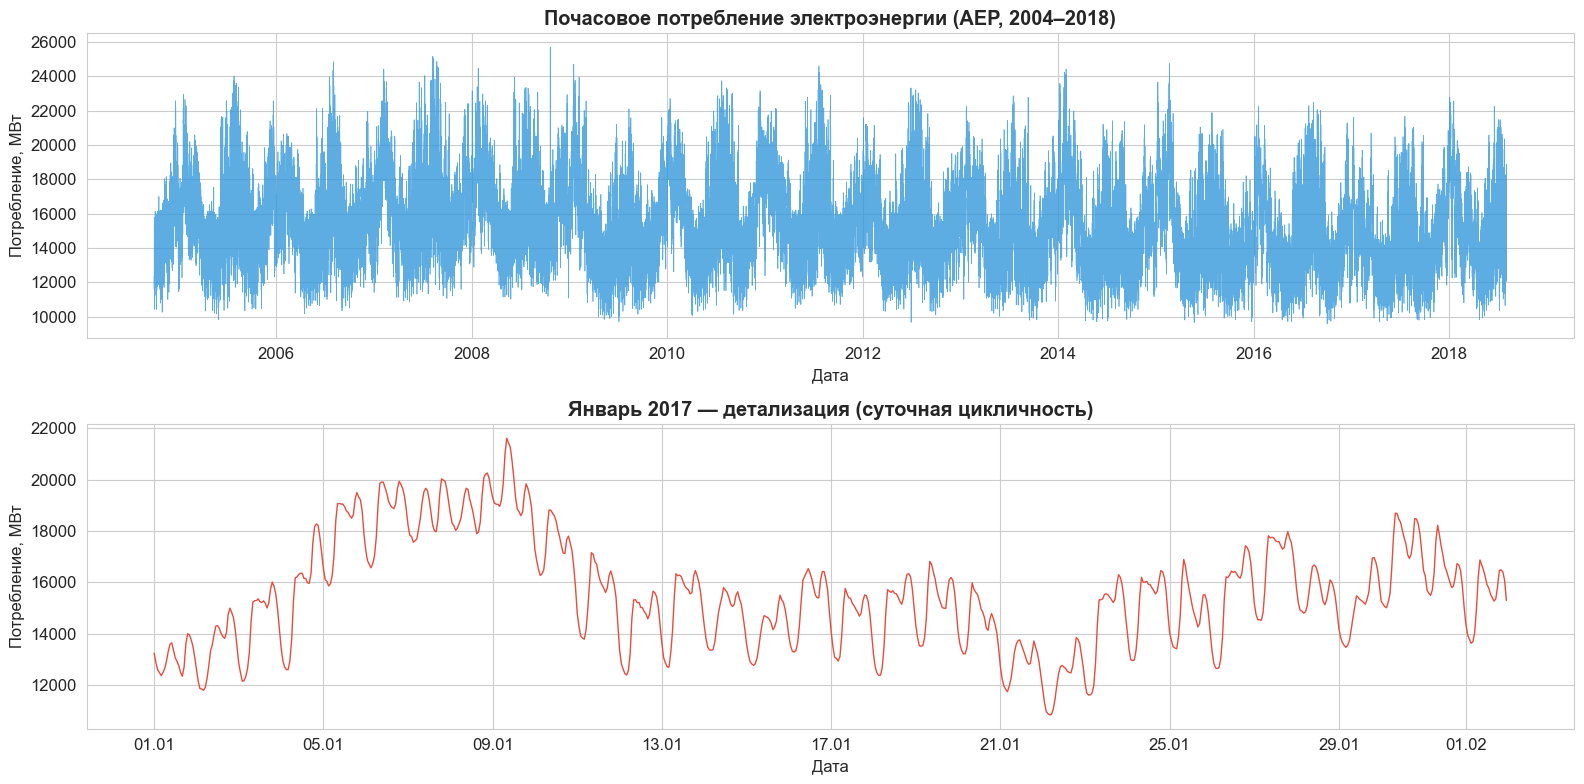

── Определение размера скользящего окна ──────────────────────
Период записи: 1 час
Наблюдений в сутках: 24
Наблюдений в неделе: 24 × 7 = 168

Цель: предсказать потребление через 1 час на основе 7 дней истории
SEQ_LENGTH = 24 × 7 = 168 наблюдений (одна неделя)


In [6]:
# ── Один признак: MW (потребление электроэнергии) ─────────────────
series = df['MW'].copy()

# ── Визуализация всего ряда ───────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(16, 8))

# Весь ряд
axes[0].plot(series.index, series.values, color='#3498db', linewidth=0.5, alpha=0.8)
axes[0].set_title('Почасовое потребление электроэнергии (AEP, 2004–2018)', fontweight='bold')
axes[0].set_ylabel('Потребление, МВт')
axes[0].set_xlabel('Дата')

# Один месяц — детально
sample = series['2017-01-01':'2017-02-01']
axes[1].plot(sample.index, sample.values, color='#e74c3c', linewidth=1)
axes[1].set_title('Январь 2017 — детализация (суточная цикличность)', fontweight='bold')
axes[1].set_ylabel('Потребление, МВт')
axes[1].set_xlabel('Дата')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))

plt.tight_layout()
plt.show()

# ── Определение размера скользящего окна ─────────────────────────
print('── Определение размера скользящего окна ──────────────────────')
print('Период записи: 1 час')
print('Наблюдений в сутках: 24')
print('Наблюдений в неделе: 24 × 7 = 168')
print()
print('Цель: предсказать потребление через 1 час на основе 7 дней истории')
print('SEQ_LENGTH = 24 × 7 = 168 наблюдений (одна неделя)')

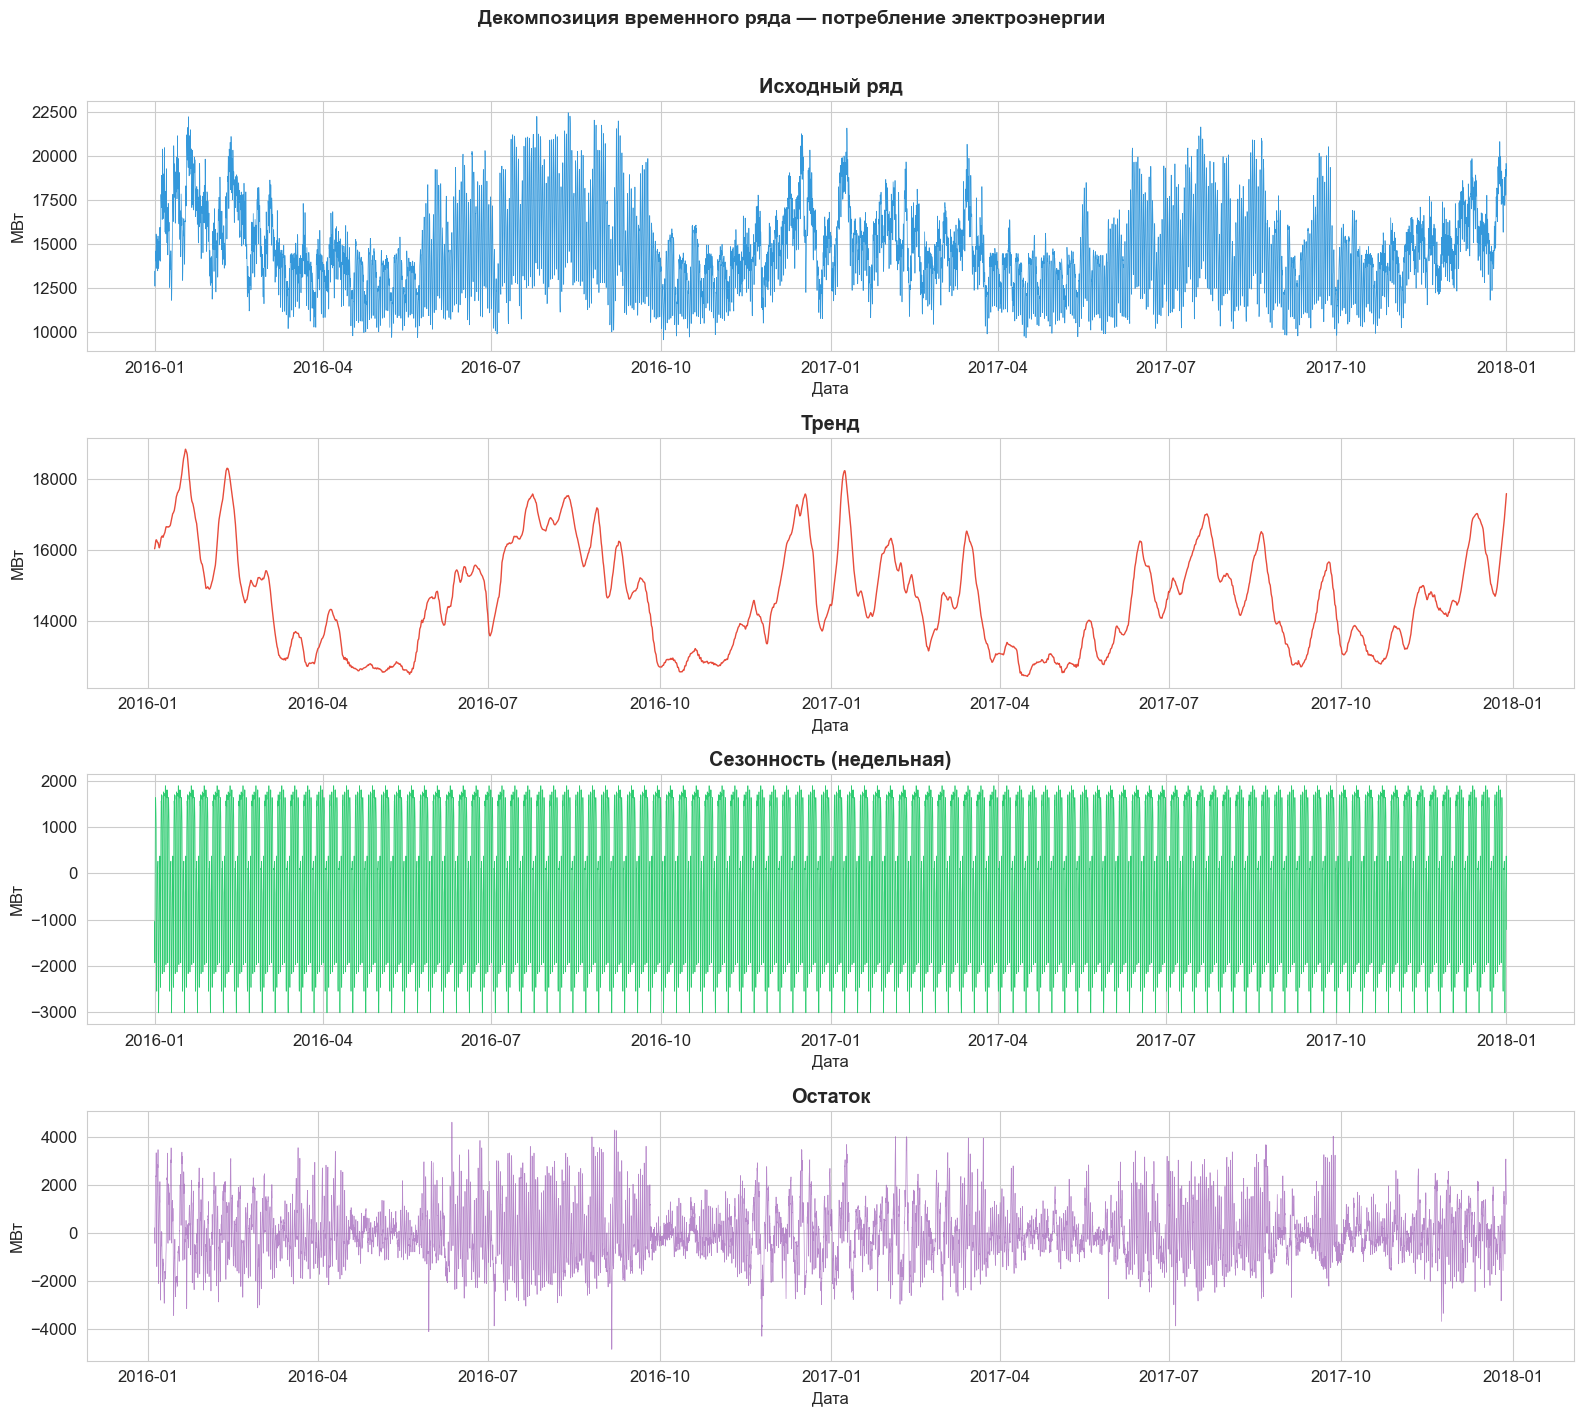

Вывод:
  Тренд: годовая цикличность (лето/зима — пики потребления)
  Сезонность: выраженный недельный паттерн (рабочие/выходные дни)
  Остаток: случайные колебания вокруг нуля — ряд хорошо декомпозируется


In [7]:
# ── Декомпозиция временного ряда ─────────────────────────────────
# Берём 2 года для наглядности (весь ряд очень долго)
series_2yr = series['2016-01-01':'2017-12-31'].dropna()

decomposition = seasonal_decompose(
    series_2yr,
    model='additive',
    period=24 * 7    # недельная сезонность
)

fig, axes = plt.subplots(4, 1, figsize=(16, 14))

axes[0].plot(series_2yr.index, series_2yr.values, color='#3498db', linewidth=0.5)
axes[0].set_title('Исходный ряд', fontweight='bold')
axes[0].set_ylabel('МВт')

axes[1].plot(decomposition.trend.index, decomposition.trend.values,
             color='#e74c3c', linewidth=1)
axes[1].set_title('Тренд', fontweight='bold')
axes[1].set_ylabel('МВт')

axes[2].plot(decomposition.seasonal.index, decomposition.seasonal.values,
             color='#2ecc71', linewidth=0.5)
axes[2].set_title('Сезонность (недельная)', fontweight='bold')
axes[2].set_ylabel('МВт')

axes[3].plot(decomposition.resid.index, decomposition.resid.values,
             color='#9b59b6', linewidth=0.5, alpha=0.7)
axes[3].set_title('Остаток', fontweight='bold')
axes[3].set_ylabel('МВт')

for ax in axes:
    ax.set_xlabel('Дата')

plt.suptitle('Декомпозиция временного ряда — потребление электроэнергии',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('Вывод:')
print('  Тренд: годовая цикличность (лето/зима — пики потребления)')
print('  Сезонность: выраженный недельный паттерн (рабочие/выходные дни)')
print('  Остаток: случайные колебания вокруг нуля — ряд хорошо декомпозируется')

### 1.2 Подготовка данных

In [8]:
# ── Параметры ─────────────────────────────────────────────────────
SEQ_LENGTH       = 168    # 7 дней × 24 часа = одна неделя
FORECAST_HORIZON = 24     # горизонт прогноза для задания 2 (1 сутки)
TRAIN_SPLIT      = 0.8    # 80% train / 20% test
EPOCHS           = 50
BATCH_SIZE       = 64

# ── Нормализация [0, 1] ───────────────────────────────────────────
scaler = MinMaxScaler(feature_range=(0, 1))
values = series.values.reshape(-1, 1)
scaled = scaler.fit_transform(values).flatten()

print(f'Нормализованные значения: min={scaled.min():.4f}, max={scaled.max():.4f}')

# ── Создание последовательностей (точечный прогноз) ───────────────
def create_sequences(data, seq_length):
    """Создаёт последовательности для точечного прогноза.
    X[i] = data[i : i+seq_length]
    y[i] = data[i + seq_length]  (одно следующее значение)
    """
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)


X, y = create_sequences(scaled, SEQ_LENGTH)
print(f'Всего последовательностей: {len(X)}')
print(f'Форма X: {X.shape}  (samples, seq_length)')
print(f'Форма y: {y.shape}  (samples,)')

# ── Разделение train / test ───────────────────────────────────────
split = int(len(X) * TRAIN_SPLIT)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# RNN ожидает форму (samples, timesteps, features)
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test  = X_test.reshape(X_test.shape[0],  X_test.shape[1],  1)

print(f'\n── Разделение данных ──────────────────────────────────────')
print(f'  Train: {X_train.shape}  |  y_train: {y_train.shape}')
print(f'  Test:  {X_test.shape}   |  y_test:  {y_test.shape}')

Нормализованные значения: min=0.0000, max=1.0000
Всего последовательностей: 121105
Форма X: (121105, 168)  (samples, seq_length)
Форма y: (121105,)  (samples,)

── Разделение данных ──────────────────────────────────────
  Train: (96884, 168, 1)  |  y_train: (96884,)
  Test:  (24221, 168, 1)   |  y_test:  (24221,)


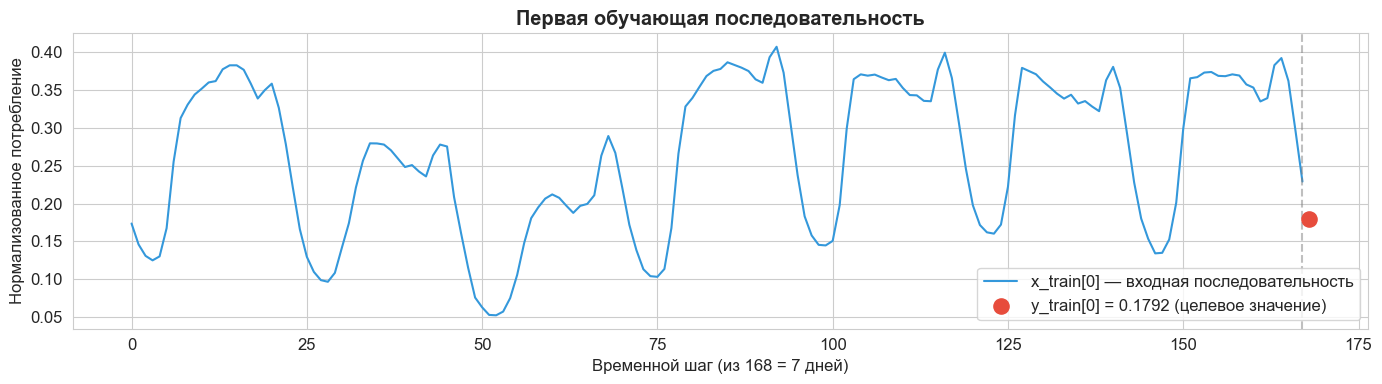

In [9]:
# ── Визуализация первой последовательности ────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(range(SEQ_LENGTH), X_train[0].flatten(),
        color='#3498db', linewidth=1.5, label='x_train[0] — входная последовательность')
ax.scatter([SEQ_LENGTH], [y_train[0]],
           color='#e74c3c', s=120, zorder=5,
           label=f'y_train[0] = {y_train[0]:.4f} (целевое значение)')
ax.axvline(SEQ_LENGTH - 1, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Первая обучающая последовательность', fontweight='bold')
ax.set_xlabel(f'Временной шаг (из {SEQ_LENGTH} = 7 дней)')
ax.set_ylabel('Нормализованное потребление')
ax.legend()
plt.tight_layout()
plt.show()

### 1.3 Вспомогательные функции

In [10]:
LOG_FILE    = 'lab5_log.json'
results_log = []

def save_log():
    with open(LOG_FILE, 'w', encoding='utf-8') as f:
        json.dump(results_log, f, ensure_ascii=False, indent=2)


def evaluate_model(model, X_test, y_test, name):
    """Метрики + обратное масштабирование."""
    y_pred_scaled = model.predict(X_test, verbose=0).flatten()
    # Обратное масштабирование
    y_pred = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
    y_true = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    entry = {
        'name':      name,
        'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M'),
        'MSE':  round(float(mse),  2),
        'RMSE': round(float(rmse), 2),
        'MAE':  round(float(mae),  2),
        'MAPE': round(float(mape), 4),
    }
    results_log.append(entry)
    save_log()

    print(f'\n── Метрики: {name} ──────────────────────────────────────')
    print(f'  MSE  = {mse:10.2f}')
    print(f'  RMSE = {rmse:10.2f} МВт')
    print(f'  MAE  = {mae:10.2f} МВт')
    print(f'  MAPE = {mape:10.4f} %')
    return y_true, y_pred


def plot_history(history, title=''):
    plt.figure(figsize=(12, 4))
    plt.plot(history.history['loss'],     label='Train Loss', color='#3498db')
    plt.plot(history.history['val_loss'], label='Val Loss',   color='#e74c3c')
    plt.title(f'{title} — Loss (MSE)', fontweight='bold')
    plt.xlabel('Эпоха')
    plt.ylabel('MSE')
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_prediction(model, X_test, y_test, name, sample_idx=0):
    """Визуализация одного предсказания: последовательность + точки."""
    seq   = X_test[sample_idx].flatten()  # нормализованная последовательность
    y_true_s = y_test[sample_idx]
    y_pred_s = model.predict(X_test[sample_idx:sample_idx+1], verbose=0).flatten()[0]

    # Обратное масштабирование
    seq_mw    = scaler.inverse_transform(seq.reshape(-1, 1)).flatten()
    true_mw   = scaler.inverse_transform([[y_true_s]])[0][0]
    pred_mw   = scaler.inverse_transform([[y_pred_s]])[0][0]

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(range(SEQ_LENGTH), seq_mw, color='#3498db', linewidth=1.5,
            label='Входная последовательность (7 дней)')
    ax.scatter([SEQ_LENGTH], [true_mw], color='#2ecc71', s=150, zorder=5,
               label=f'Истинное: {true_mw:.1f} МВт')
    ax.scatter([SEQ_LENGTH], [pred_mw], color='#e74c3c', s=150,
               marker='X', zorder=5,
               label=f'Предсказанное: {pred_mw:.1f} МВт')
    ax.axvline(SEQ_LENGTH - 1, color='gray', linestyle='--', alpha=0.4)
    ax.set_title(f'{name} — предсказание для последовательности #{sample_idx}',
                 fontweight='bold')
    ax.set_xlabel('Временной шаг')
    ax.set_ylabel('Потребление, МВт')
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(f'  Ошибка: {abs(true_mw - pred_mw):.1f} МВт  ({abs(true_mw-pred_mw)/true_mw*100:.2f}%)')


def plot_test_forecast(y_true, y_pred, name, n=500):
    """Предсказания vs реальные значения на тестовой выборке."""
    plt.figure(figsize=(14, 4))
    plt.plot(y_true[:n], label='Реальные значения', color='#3498db', linewidth=1)
    plt.plot(y_pred[:n], label='Предсказания',       color='#e74c3c', linewidth=1, alpha=0.8)
    plt.title(f'{name} — прогноз на тестовой выборке (первые {n} точек)',
              fontweight='bold')
    plt.xlabel('Временной шаг')
    plt.ylabel('Потребление, МВт')
    plt.legend()
    plt.tight_layout()
    plt.show()


# Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=5, min_lr=1e-6, verbose=1)
]

print('Вспомогательные функции определены.')

Вспомогательные функции определены.


### 1.4 Модель 1 — Однослойная SimpleRNN

In [11]:
# ── Архитектура: SimpleRNN(50) → Dropout(0.2) → Dense(25) → Dense(1)
model_rnn1 = Sequential([
    SimpleRNN(50, input_shape=(SEQ_LENGTH, 1), return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
model_rnn1.compile(optimizer='adam', loss='mean_squared_error')
model_rnn1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,901 (15.24 KB)

 Trainable params: 3,901 (15.24 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - loss: 0.0035 - val_loss: 4.6626e-04 - learning_rate: 0.0010
Epoch 2/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - loss: 6.3255e-04 - val_loss: 2.9700e-04 - learning_rate: 0.0010
Epoch 3/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - loss: 4.5234e-04 - val_loss: 1.7794e-04 - learning_rate: 0.0010
Epoch 4/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - loss: 3.7838e-04 - val_loss: 2.7517e-04 - learning_rate: 0.0010
Epoch 5/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 3.5288e-04 - val_loss: 2.7242e-04 - learning_rate: 0.0010
Epoch 6/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - loss: 3.2124e-04 - val_loss: 2.7715e-04 - learning_rate: 0.0010
Epoch 7/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - loss: 2.9464e-04 - val_loss: 4.4934e-04 - learning_rate: 0.0010
Epoch 8/50
1361/1363 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2.6615e-04
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.


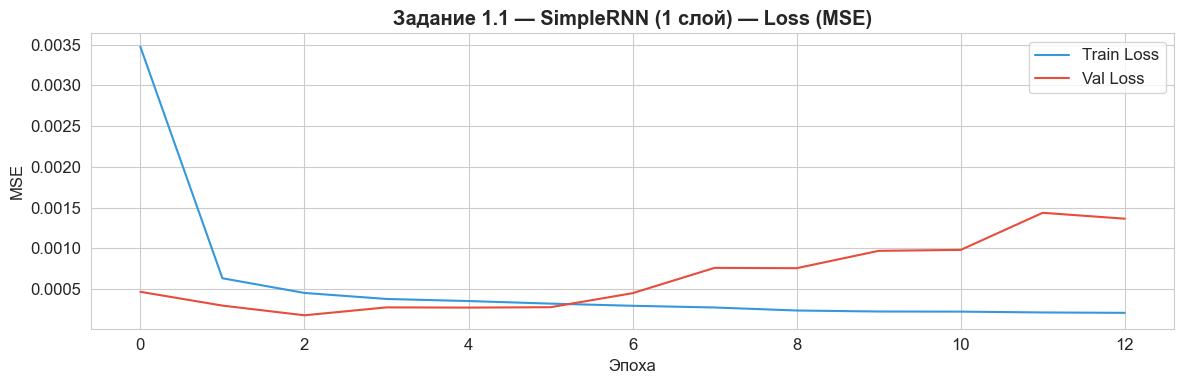


── Метрики: SimpleRNN 1 слой ──────────────────────────────────────
  MSE  =   44893.04
  RMSE =     211.88 МВт
  MAE  =     160.80 МВт
  MAPE =     1.1164 %


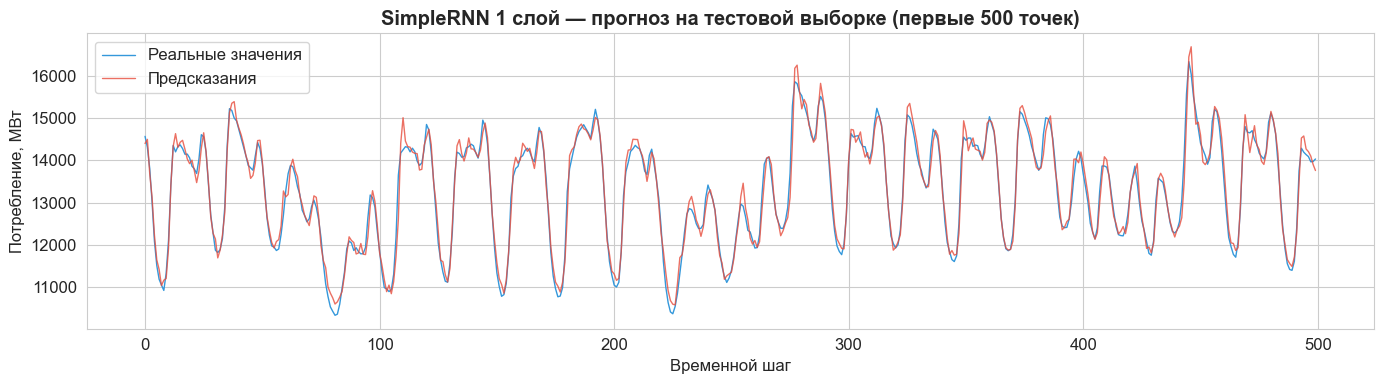

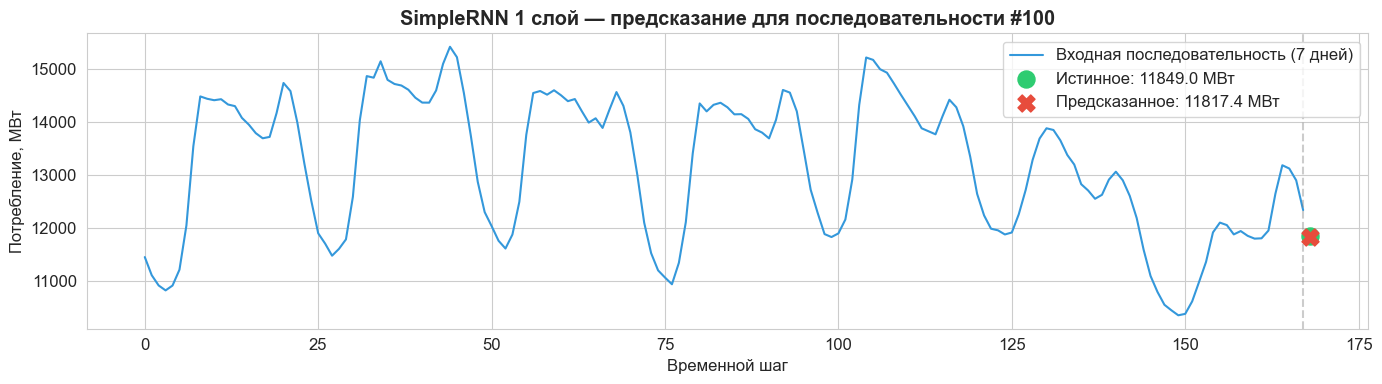

  Ошибка: 31.6 МВт  (0.27%)


In [12]:
history_rnn1 = model_rnn1.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

plot_history(history_rnn1, 'Задание 1.1 — SimpleRNN (1 слой)')
y_true_rnn1, y_pred_rnn1 = evaluate_model(
    model_rnn1, X_test, y_test, 'SimpleRNN 1 слой'
)
plot_test_forecast(y_true_rnn1, y_pred_rnn1, 'SimpleRNN 1 слой')
plot_prediction(model_rnn1, X_test, y_test, 'SimpleRNN 1 слой', sample_idx=100)

### 1.5 Модель 2 — Двухслойная SimpleRNN

In [13]:
# ── Добавляем второй SimpleRNN слой ──────────────────────────────
# return_sequences=True в первом слое — передаём последовательность дальше
model_rnn2 = Sequential([
    SimpleRNN(50, input_shape=(SEQ_LENGTH, 1), return_sequences=True),
    Dropout(0.2),
    SimpleRNN(50, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
model_rnn2.compile(optimizer='adam', loss='mean_squared_error')
model_rnn2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 168, 50)        │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 168, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,951 (34.96 KB)

 Trainable params: 8,951 (34.96 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 39s 27ms/step - loss: 0.0033 - val_loss: 7.3392e-04 - learning_rate: 0.0010
Epoch 2/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - loss: 8.5370e-04 - val_loss: 2.6919e-04 - learning_rate: 0.0010
Epoch 3/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 39s 29ms/step - loss: 5.7844e-04 - val_loss: 1.9780e-04 - learning_rate: 0.0010
Epoch 4/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 39s 29ms/step - loss: 4.8281e-04 - val_loss: 2.5804e-04 - learning_rate: 0.0010
Epoch 5/50
1361/1363 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 4.4189e-04
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 39s 28ms/step - loss: 4.3663e-04 - val_loss: 3.2524e-04 - learning_rate: 0.0010
Epoch 6/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - loss: 3.7571e-04 - val_loss: 1.6892e-04 - learning_rate: 5.0000e-04
Epoch 7/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 40s 30ms/step - loss: 3.5306e-04 - val_loss: 2.3029e-04 - learning_rate: 5.0000e-04
Epo

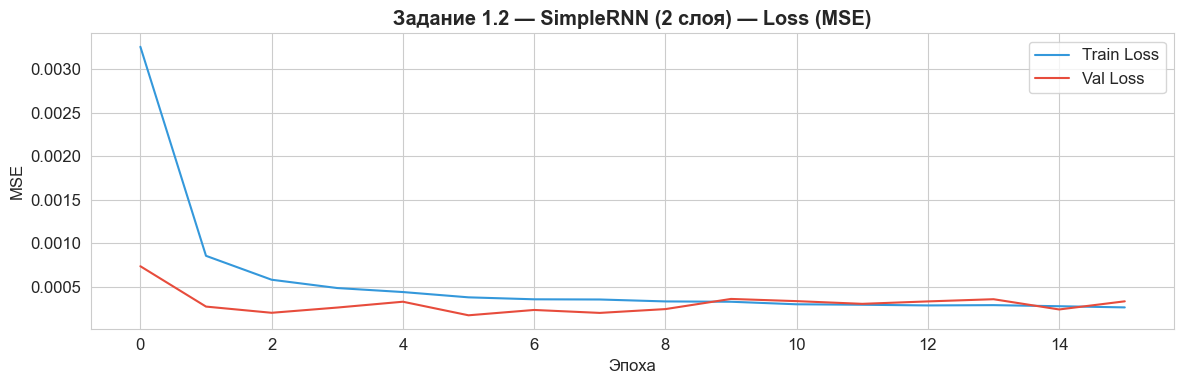


── Метрики: SimpleRNN 2 слоя ──────────────────────────────────────
  MSE  =   43302.15
  RMSE =     208.09 МВт
  MAE  =     158.39 МВт
  MAPE =     1.1184 %


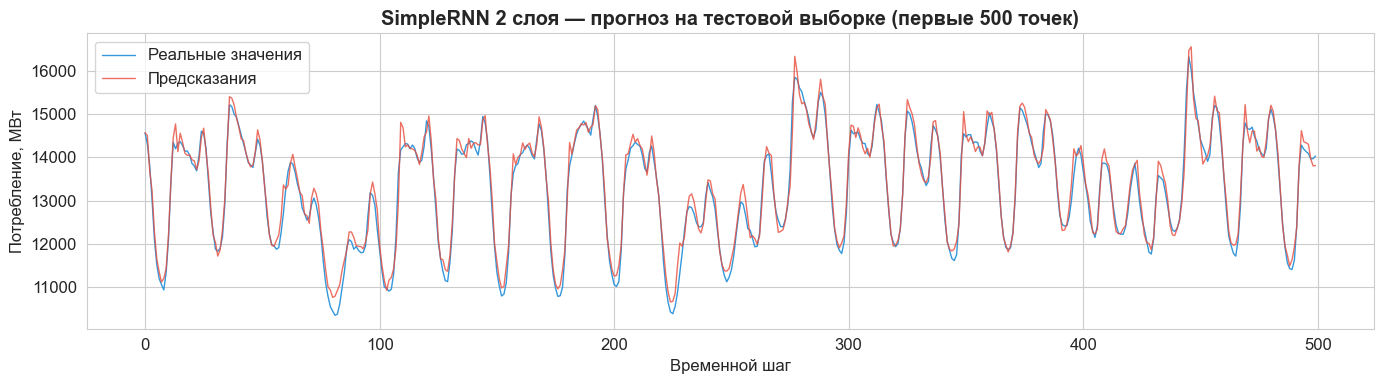

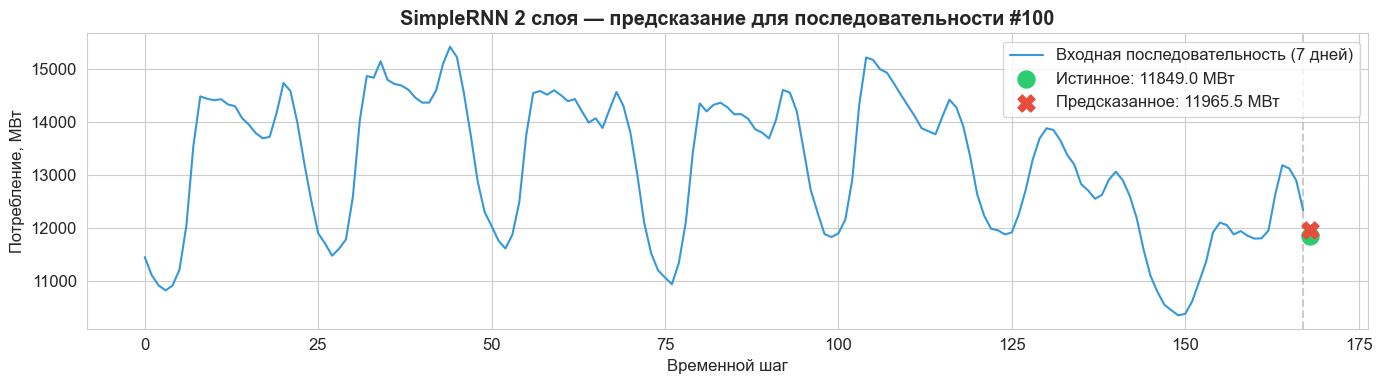

  Ошибка: 116.5 МВт  (0.98%)


In [14]:
history_rnn2 = model_rnn2.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

plot_history(history_rnn2, 'Задание 1.2 — SimpleRNN (2 слоя)')
y_true_rnn2, y_pred_rnn2 = evaluate_model(
    model_rnn2, X_test, y_test, 'SimpleRNN 2 слоя'
)
plot_test_forecast(y_true_rnn2, y_pred_rnn2, 'SimpleRNN 2 слоя')
plot_prediction(model_rnn2, X_test, y_test, 'SimpleRNN 2 слоя', sample_idx=100)

### 1.6 Модель 3 — Двухслойная LSTM

In [15]:
# ── LSTM решает проблему исчезающего градиента ────────────────────
model_lstm = Sequential([
    LSTM(50, input_shape=(SEQ_LENGTH, 1), return_sequences=True),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
model_lstm.compile(optimizer='adam', loss='mean_squared_error')
model_lstm.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 168, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 168, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 102s 73ms/step - loss: 0.0051 - val_loss: 5.3827e-04 - learning_rate: 0.0010
Epoch 2/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 104s 77ms/step - loss: 8.8291e-04 - val_loss: 3.8148e-04 - learning_rate: 0.0010
Epoch 3/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 106s 78ms/step - loss: 6.2796e-04 - val_loss: 2.4118e-04 - learning_rate: 0.0010
Epoch 4/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 108s 79ms/step - loss: 5.4753e-04 - val_loss: 2.6704e-04 - learning_rate: 0.0010
Epoch 5/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - loss: 5.2554e-04
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 105s 77ms/step - loss: 5.0523e-04 - val_loss: 2.1522e-04 - learning_rate: 0.0010
Epoch 6/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 109s 80ms/step - loss: 4.5386e-04 - val_loss: 2.2760e-04 - learning_rate: 5.0000e-04
Epoch 7/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 105s 77ms/step - loss: 4.3622e-04 - val_loss: 2.7130e-04 - learning_rate: 5.0000e

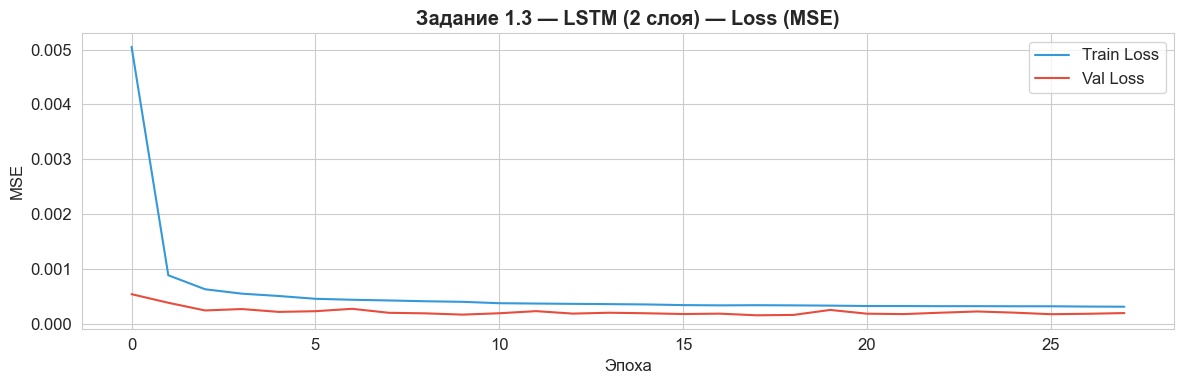


── Метрики: LSTM 2 слоя ──────────────────────────────────────
  MSE  =   39643.90
  RMSE =     199.11 МВт
  MAE  =     149.42 МВт
  MAPE =     1.0345 %


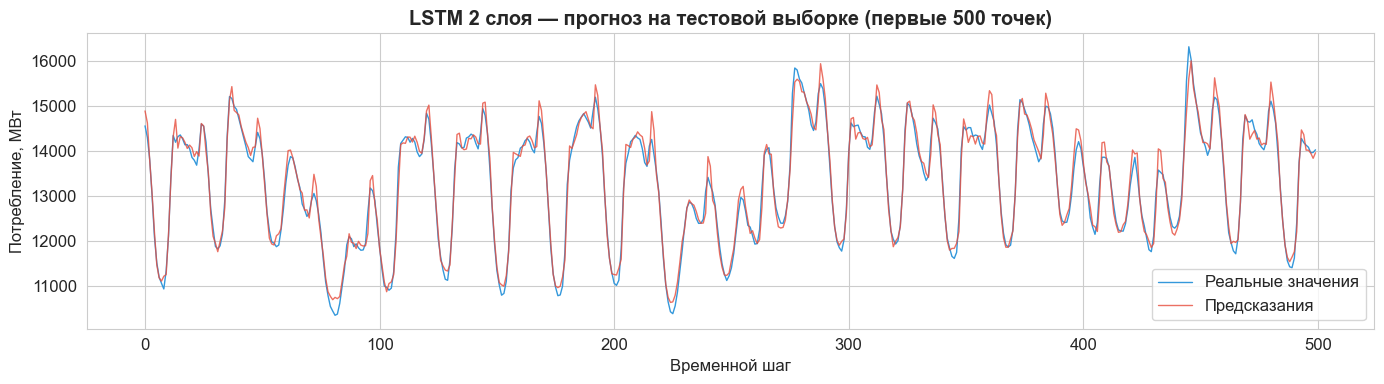

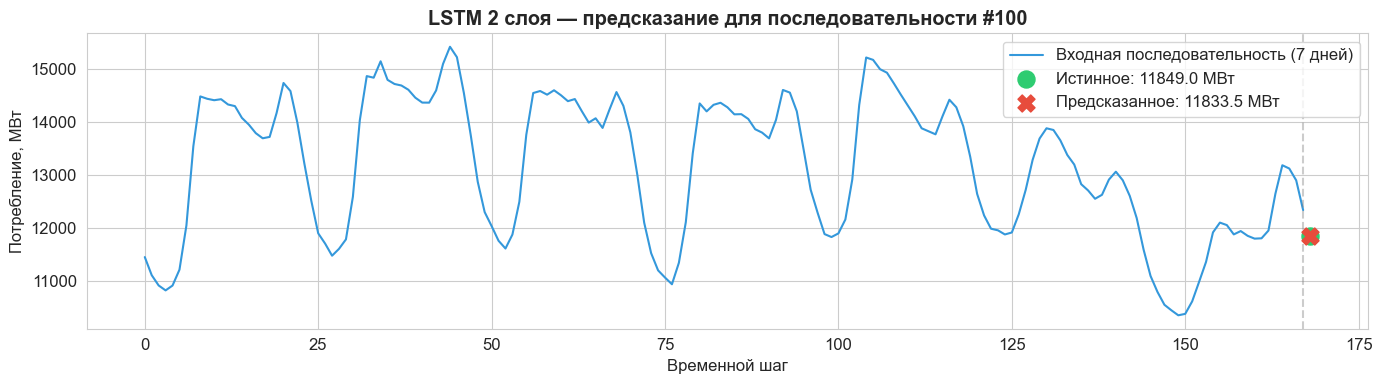

  Ошибка: 15.5 МВт  (0.13%)


In [16]:
history_lstm = model_lstm.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

plot_history(history_lstm, 'Задание 1.3 — LSTM (2 слоя)')
y_true_lstm, y_pred_lstm = evaluate_model(
    model_lstm, X_test, y_test, 'LSTM 2 слоя'
)
plot_test_forecast(y_true_lstm, y_pred_lstm, 'LSTM 2 слоя')
plot_prediction(model_lstm, X_test, y_test, 'LSTM 2 слоя', sample_idx=100)

### 1.7 Модель 4 — Двухслойная GRU

In [17]:
# ── GRU — упрощённый LSTM, меньше параметров ─────────────────────
model_gru = Sequential([
    GRU(50, input_shape=(SEQ_LENGTH, 1), return_sequences=True),
    Dropout(0.2),
    GRU(50, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
model_gru.compile(optimizer='adam', loss='mean_squared_error')
model_gru.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 168, 50)        │         7,950 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 168, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 50)             │        15,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,551 (95.90 KB)

 Trainable params: 24,551 (95.90 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 124s 89ms/step - loss: 0.0022 - val_loss: 4.5795e-04 - learning_rate: 0.0010
Epoch 2/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 123s 90ms/step - loss: 7.0191e-04 - val_loss: 3.7237e-04 - learning_rate: 0.0010
Epoch 3/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 125s 92ms/step - loss: 6.1603e-04 - val_loss: 3.7751e-04 - learning_rate: 0.0010
Epoch 4/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 138s 101ms/step - loss: 5.7610e-04 - val_loss: 3.5804e-04 - learning_rate: 0.0010
Epoch 5/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - loss: 5.5581e-04
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 133s 97ms/step - loss: 5.3963e-04 - val_loss: 3.2467e-04 - learning_rate: 0.0010
Epoch 6/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 132s 97ms/step - loss: 4.9120e-04 - val_loss: 4.9478e-04 - learning_rate: 5.0000e-04
Epoch 7/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 130s 95ms/step - loss: 4.5985e-04 - val_loss: 0.0011 - learning_rate: 5.0000e-04

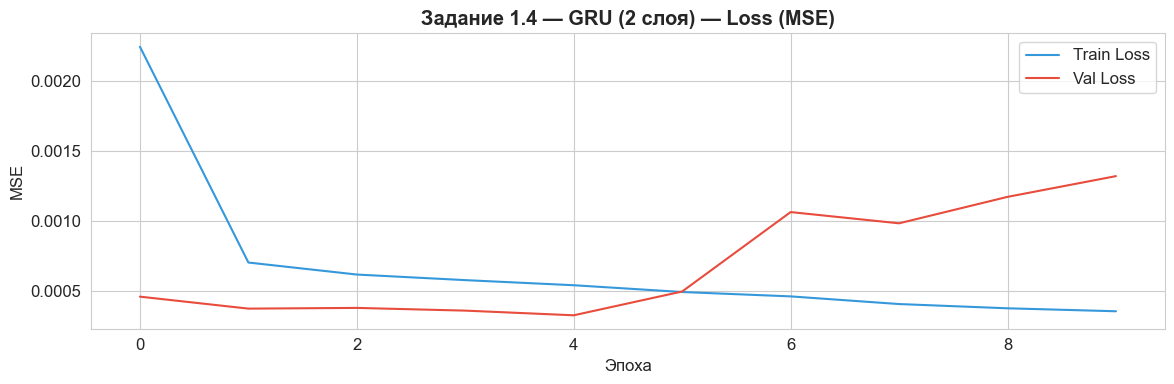


── Метрики: GRU 2 слоя ──────────────────────────────────────
  MSE  =  109707.32
  RMSE =     331.22 МВт
  MAE  =     260.64 МВт
  MAPE =     1.7696 %


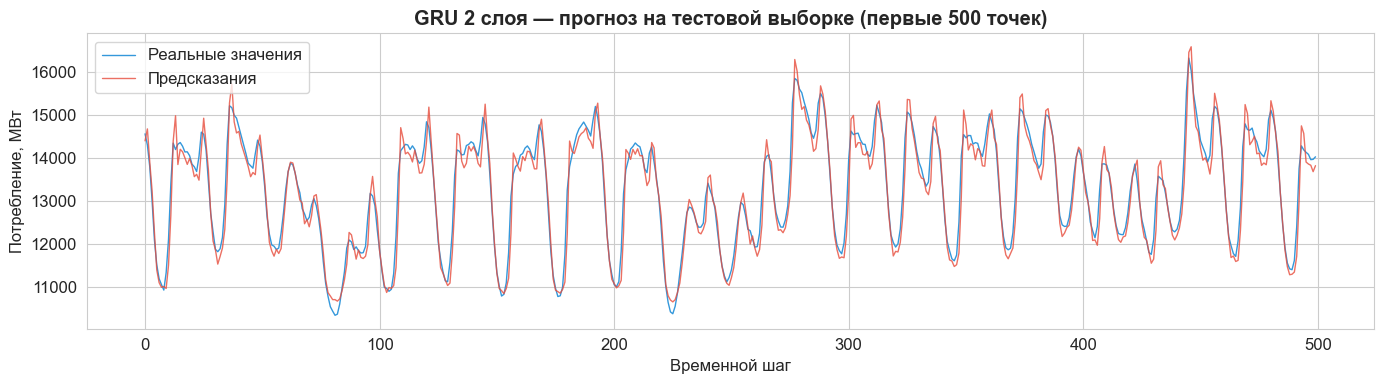

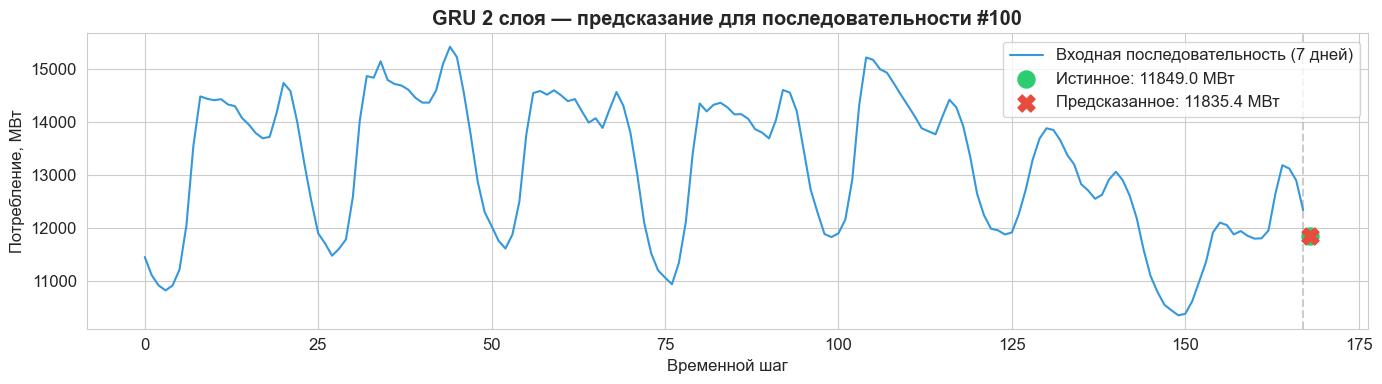

  Ошибка: 13.6 МВт  (0.11%)


In [18]:
history_gru = model_gru.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

plot_history(history_gru, 'Задание 1.4 — GRU (2 слоя)')
y_true_gru, y_pred_gru = evaluate_model(
    model_gru, X_test, y_test, 'GRU 2 слоя'
)
plot_test_forecast(y_true_gru, y_pred_gru, 'GRU 2 слоя')
plot_prediction(model_gru, X_test, y_test, 'GRU 2 слоя', sample_idx=100)

### 1.8 Сравнение всех моделей (Задание 1)

Таблица результатов — Задание 1:


,name,RMSE,MAE,MAPE,MSE
0,LSTM 2 слоя,199.11,149.42,1.0345,39643.90
1,SimpleRNN 2 слоя,208.09,158.39,1.1184,43302.15
2,SimpleRNN 1 слой,211.88,160.80,1.1164,44893.04
3,GRU 2 слоя,331.22,260.64,1.7696,109707.32


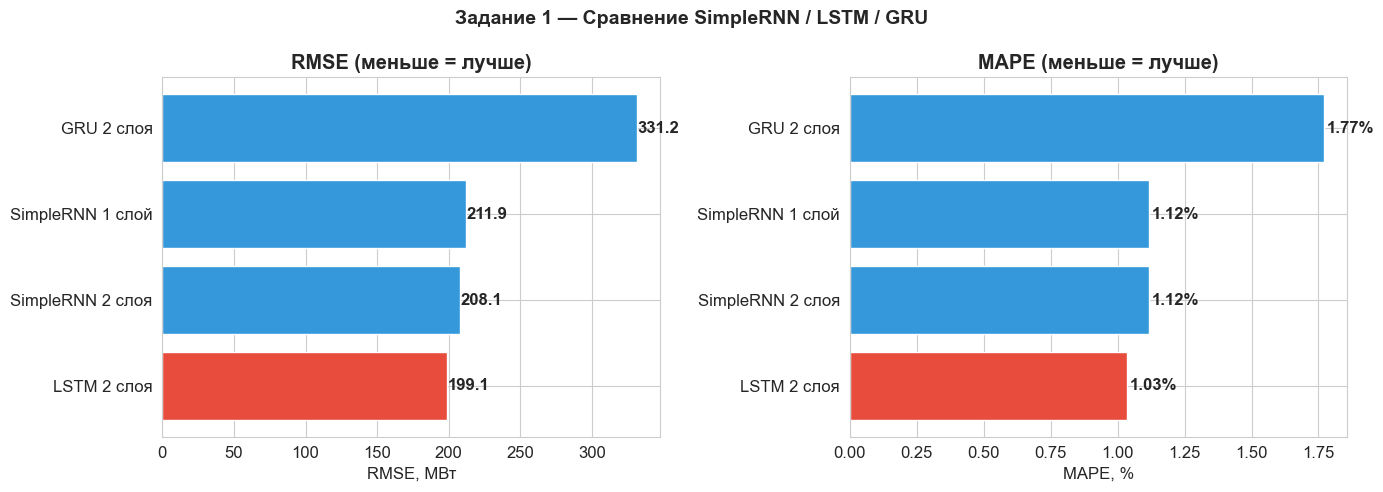

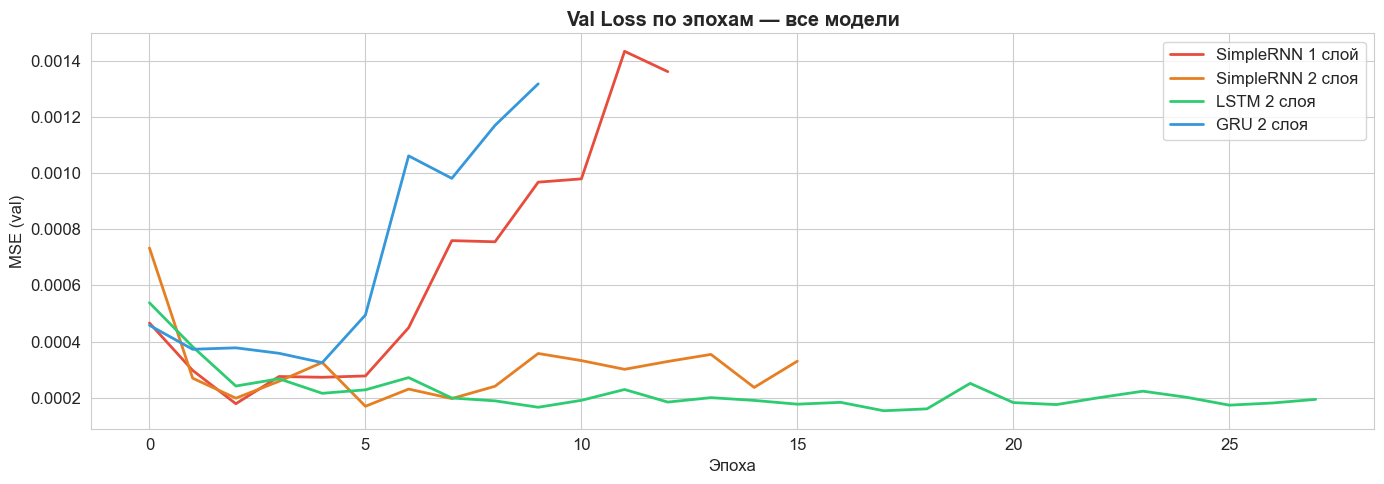


🏆 Лучшая модель: LSTM 2 слоя
   RMSE = 199.11 МВт | MAPE = 1.0345%


In [19]:
# ── Таблица метрик ────────────────────────────────────────────────
metrics_df = pd.DataFrame(results_log)[['name', 'RMSE', 'MAE', 'MAPE', 'MSE']]
metrics_df = metrics_df.sort_values('RMSE').reset_index(drop=True)
print('Таблица результатов — Задание 1:')
display(metrics_df)

# ── Сравнительный график ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

names  = metrics_df['name'].tolist()
colors = ['#e74c3c' if i == 0 else '#3498db' for i in range(len(names))]

bars = axes[0].barh(names, metrics_df['RMSE'], color=colors, edgecolor='white')
for bar, v in zip(bars, metrics_df['RMSE']):
    axes[0].text(v + 0.5, bar.get_y() + bar.get_height()/2,
                 f'{v:.1f}', va='center', fontweight='bold')
axes[0].set_title('RMSE (меньше = лучше)', fontweight='bold')
axes[0].set_xlabel('RMSE, МВт')

bars2 = axes[1].barh(names, metrics_df['MAPE'], color=colors, edgecolor='white')
for bar, v in zip(bars2, metrics_df['MAPE']):
    axes[1].text(v + 0.01, bar.get_y() + bar.get_height()/2,
                 f'{v:.2f}%', va='center', fontweight='bold')
axes[1].set_title('MAPE (меньше = лучше)', fontweight='bold')
axes[1].set_xlabel('MAPE, %')

plt.suptitle('Задание 1 — Сравнение SimpleRNN / LSTM / GRU',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ── Кривые обучения всех моделей ─────────────────────────────────
plt.figure(figsize=(14, 5))
for hist, label, color in [
    (history_rnn1, 'SimpleRNN 1 слой',  '#e74c3c'),
    (history_rnn2, 'SimpleRNN 2 слоя',  '#e67e22'),
    (history_lstm, 'LSTM 2 слоя',       '#2ecc71'),
    (history_gru,  'GRU 2 слоя',        '#3498db'),
]:
    plt.plot(hist.history['val_loss'], label=label, color=color, linewidth=2)

plt.title('Val Loss по эпохам — все модели', fontweight='bold')
plt.xlabel('Эпоха')
plt.ylabel('MSE (val)')
plt.legend()
plt.tight_layout()
plt.show()

best = metrics_df.iloc[0]
print(f'\n🏆 Лучшая модель: {best["name"]}')
print(f'   RMSE = {best["RMSE"]:.2f} МВт | MAPE = {best["MAPE"]:.4f}%')

---
## Задание 2. Интервальный прогноз по одному признаку
### 2.1 Подготовка данных

Форма X: (121082, 168)  — (samples, 168 часов входа)
Форма y: (121082, 24)  — (samples, 24 часов прогноза)

Train: (96865, 168, 1) | Test: (24217, 168, 1)
y_train: (96865, 24) | y_test: (24217, 24)


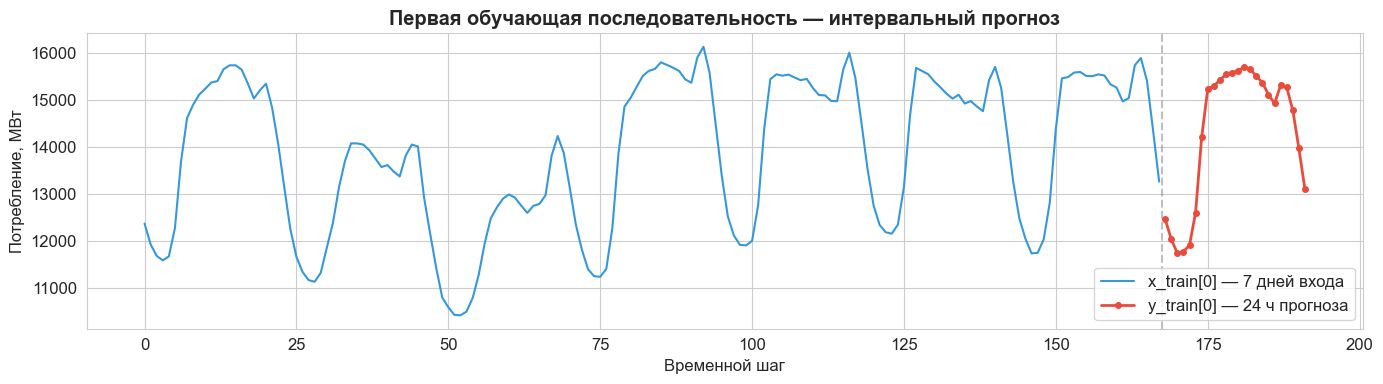

In [20]:
# ── Создание последовательностей для интервального прогноза ───────
def create_sequences_interval(data, seq_length, forecast_horizon):
    """
    X[i] = data[i : i+seq_length]           (входное окно)
    y[i] = data[i+seq_length : i+seq_length+forecast_horizon]  (горизонт)
    """
    X, y = [], []
    for i in range(len(data) - seq_length - forecast_horizon + 1):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length : i + seq_length + forecast_horizon])
    return np.array(X), np.array(y)


X_int, y_int = create_sequences_interval(scaled, SEQ_LENGTH, FORECAST_HORIZON)
print(f'Форма X: {X_int.shape}  — (samples, {SEQ_LENGTH} часов входа)')
print(f'Форма y: {y_int.shape}  — (samples, {FORECAST_HORIZON} часов прогноза)')

# ── Разделение train / test ───────────────────────────────────────
split_int = int(len(X_int) * TRAIN_SPLIT)
X_train_i, X_test_i = X_int[:split_int], X_int[split_int:]
y_train_i, y_test_i = y_int[:split_int], y_int[split_int:]

X_train_i = X_train_i.reshape(X_train_i.shape[0], X_train_i.shape[1], 1)
X_test_i  = X_test_i.reshape(X_test_i.shape[0],  X_test_i.shape[1],  1)

print(f'\nTrain: {X_train_i.shape} | Test: {X_test_i.shape}')
print(f'y_train: {y_train_i.shape} | y_test: {y_test_i.shape}')

# ── Визуализация первой последовательности ────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))

x0_mw = scaler.inverse_transform(X_train_i[0].reshape(-1,1)).flatten()
y0_mw = scaler.inverse_transform(y_train_i[0].reshape(-1,1)).flatten()

ax.plot(range(SEQ_LENGTH), x0_mw,
        color='#3498db', linewidth=1.5, label='x_train[0] — 7 дней входа')
ax.plot(range(SEQ_LENGTH, SEQ_LENGTH + FORECAST_HORIZON), y0_mw,
        color='#e74c3c', linewidth=2, marker='o', markersize=4,
        label=f'y_train[0] — {FORECAST_HORIZON} ч прогноза')
ax.axvline(SEQ_LENGTH - 0.5, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Первая обучающая последовательность — интервальный прогноз',
             fontweight='bold')
ax.set_xlabel('Временной шаг')
ax.set_ylabel('Потребление, МВт')
ax.legend()
plt.tight_layout()
plt.show()

### 2.2 Двухслойная LSTM для интервального прогноза

In [21]:
# ── Архитектура: выход = FORECAST_HORIZON значений ────────────────
model_lstm_int = Sequential([
    LSTM(50, input_shape=(SEQ_LENGTH, 1), return_sequences=True),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(50, activation='relu'),
    Dense(FORECAST_HORIZON)   # выход = 24 значения (следующие сутки)
])
model_lstm_int.compile(optimizer='adam', loss='mean_squared_error')
model_lstm_int.summary()
print(f'\nВыходной слой: {FORECAST_HORIZON} нейронов = прогноз на {FORECAST_HORIZON} часов вперёд')

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 168, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 168, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 24)             │         1,224 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,374 (134.27 KB)

 Trainable params: 34,374 (134.27 KB)

 Non-trainable params: 0 (0.00 B)


Выходной слой: 24 нейронов = прогноз на 24 часов вперёд


Epoch 1/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 100s 71ms/step - loss: 0.0105 - val_loss: 0.0058 - learning_rate: 0.0010
Epoch 2/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 103s 76ms/step - loss: 0.0056 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 3/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 102s 75ms/step - loss: 0.0044 - val_loss: 0.0034 - learning_rate: 0.0010
Epoch 4/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 109s 80ms/step - loss: 0.0039 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 5/50
1362/1363 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 0.0037
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 108s 80ms/step - loss: 0.0037 - val_loss: 0.0030 - learning_rate: 0.0010
Epoch 6/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 109s 80ms/step - loss: 0.0033 - val_loss: 0.0027 - learning_rate: 5.0000e-04
Epoch 7/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 105s 77ms/step - loss: 0.0032 - val_loss: 0.0029 - learning_rate: 5.0000e-04
Epoch 8/50
1363/1363 ━━━━━━━━━━━━━━━━━━━━ 107s 78ms/

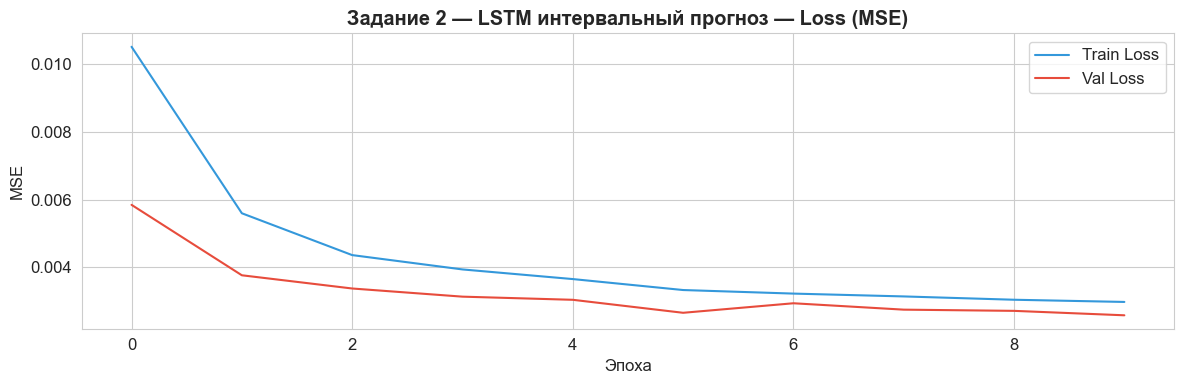


── Метрики: LSTM интервальный (24ч) ──────────────────
  RMSE = 1199.21 МВт
  MAE  = 955.28 МВт
  MAPE = 6.7359 %


In [22]:
history_lstm_int = model_lstm_int.fit(
    X_train_i, y_train_i,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

plot_history(history_lstm_int, 'Задание 2 — LSTM интервальный прогноз')

# ── Метрики на тесте ──────────────────────────────────────────────
y_pred_int = model_lstm_int.predict(X_test_i, verbose=0)

y_pred_mw = scaler.inverse_transform(y_pred_int.reshape(-1,1)).reshape(y_pred_int.shape)
y_true_mw = scaler.inverse_transform(y_test_i.reshape(-1,1)).reshape(y_test_i.shape)

mse_int  = mean_squared_error(y_true_mw.flatten(), y_pred_mw.flatten())
rmse_int = np.sqrt(mse_int)
mae_int  = mean_absolute_error(y_true_mw.flatten(), y_pred_mw.flatten())
mape_int = np.mean(np.abs((y_true_mw - y_pred_mw) / y_true_mw)) * 100

print(f'\n── Метрики: LSTM интервальный ({FORECAST_HORIZON}ч) ──────────────────')
print(f'  RMSE = {rmse_int:.2f} МВт')
print(f'  MAE  = {mae_int:.2f} МВт')
print(f'  MAPE = {mape_int:.4f} %')

results_log.append({
    'name': f'LSTM интервальный ({FORECAST_HORIZON}ч)',
    'MSE': round(mse_int, 2), 'RMSE': round(rmse_int, 2),
    'MAE': round(mae_int, 2), 'MAPE': round(mape_int, 4)
})
save_log()

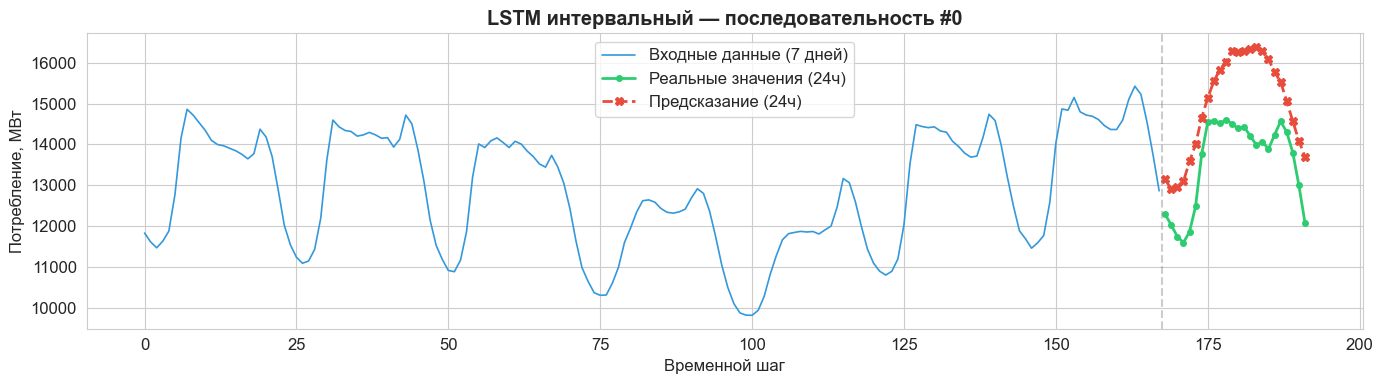

  Последовательность #0: MAE = 1414.2 МВт


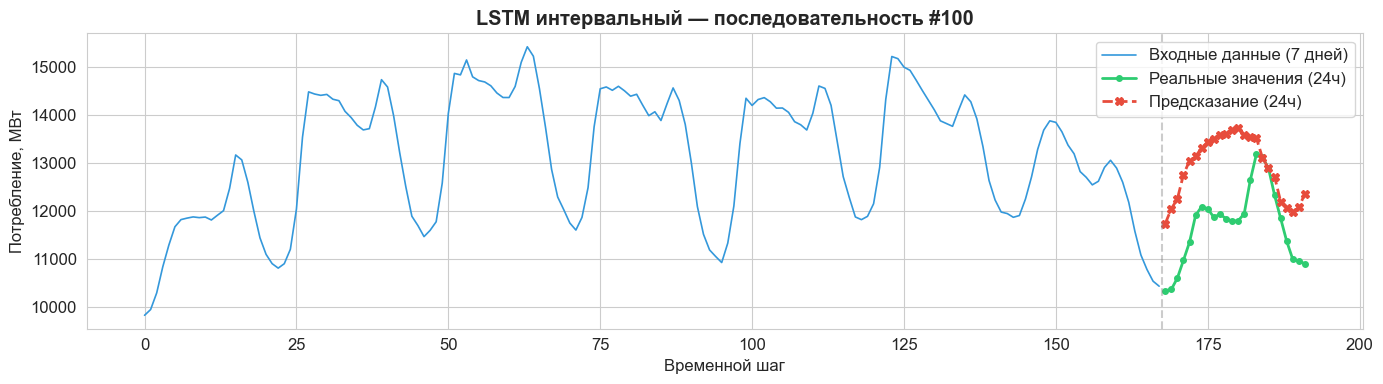

  Последовательность #100: MAE = 1199.1 МВт


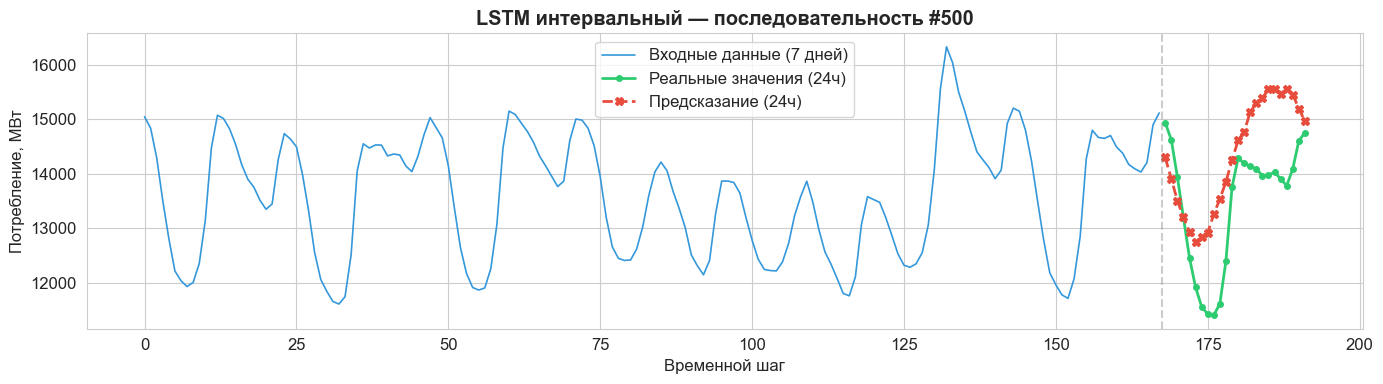

  Последовательность #500: MAE = 1029.0 МВт


In [23]:
# ── Визуализация 3 предсказаний ───────────────────────────────────
sample_indices = [0, 100, 500]

for idx in sample_indices:
    x_seq  = scaler.inverse_transform(X_test_i[idx].reshape(-1,1)).flatten()
    y_true_seq = scaler.inverse_transform(y_test_i[idx].reshape(-1,1)).flatten()
    y_pred_seq = scaler.inverse_transform(
        model_lstm_int.predict(X_test_i[idx:idx+1], verbose=0).flatten().reshape(-1,1)
    ).flatten()

    fig, ax = plt.subplots(figsize=(14, 4))
    t_input    = range(SEQ_LENGTH)
    t_forecast = range(SEQ_LENGTH, SEQ_LENGTH + FORECAST_HORIZON)

    ax.plot(t_input,    x_seq,      color='#3498db', linewidth=1.2,
            label='Входные данные (7 дней)')
    ax.plot(t_forecast, y_true_seq, color='#2ecc71', linewidth=2,
            marker='o', markersize=4, label='Реальные значения (24ч)')
    ax.plot(t_forecast, y_pred_seq, color='#e74c3c', linewidth=2,
            marker='X', markersize=6, linestyle='--',
            label='Предсказание (24ч)')
    ax.axvline(SEQ_LENGTH - 0.5, color='gray', linestyle='--', alpha=0.4)
    ax.set_title(f'LSTM интервальный — последовательность #{idx}', fontweight='bold')
    ax.set_xlabel('Временной шаг')
    ax.set_ylabel('Потребление, МВт')
    ax.legend()
    plt.tight_layout()
    plt.show()

    err = np.mean(np.abs(y_true_seq - y_pred_seq))
    print(f'  Последовательность #{idx}: MAE = {err:.1f} МВт')

---
## Итоговое сравнение

Итоговая таблица всех моделей:


,name,RMSE,MAE,MAPE
0,SimpleRNN 1 слой,211.88,160.80,1.1164
1,SimpleRNN 2 слоя,208.09,158.39,1.1184
2,LSTM 2 слоя,199.11,149.42,1.0345
3,GRU 2 слоя,331.22,260.64,1.7696
4,LSTM интервальный (24ч),1199.21,955.28,6.7359


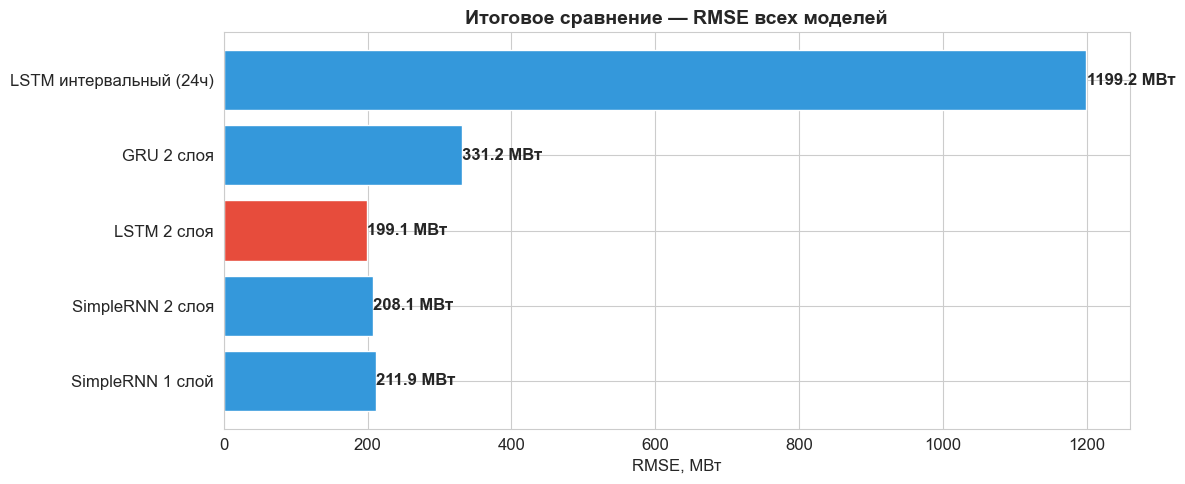


🏆 Лучшая модель: LSTM 2 слоя
   RMSE=199.11 МВт | MAE=149.42 МВт | MAPE=1.0345%

Лог сохранён: lab5_log.json


In [24]:
final_df = pd.DataFrame(results_log)[['name', 'RMSE', 'MAE', 'MAPE']]
print('Итоговая таблица всех моделей:')
display(final_df)

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#e74c3c' if i == final_df['RMSE'].values.argmin() else '#3498db'
          for i in range(len(final_df))]
bars = ax.barh(final_df['name'], final_df['RMSE'], color=colors, edgecolor='white')
for bar, v in zip(bars, final_df['RMSE']):
    ax.text(v + 0.2, bar.get_y() + bar.get_height()/2,
            f'{v:.1f} МВт', va='center', fontweight='bold')
ax.set_title('Итоговое сравнение — RMSE всех моделей', fontsize=14, fontweight='bold')
ax.set_xlabel('RMSE, МВт')
plt.tight_layout()
plt.show()

best = final_df.loc[final_df['RMSE'].idxmin()]
print(f'\n🏆 Лучшая модель: {best["name"]}')
print(f'   RMSE={best["RMSE"]:.2f} МВт | MAE={best["MAE"]:.2f} МВт | MAPE={best["MAPE"]:.4f}%')
print(f'\nЛог сохранён: {LOG_FILE}')